# MI Part 3: Neural Models Integration
**Provider Network Access and Cost Planner** · David Satizabal · CAI4510C Machine Intelligence

This Part takes the MI Part 2 pipeline and asks three questions:
1. **Does a neural network beat the MI Part 2 champion** (balanced logistic regression) on the high-cost flag? → **MLP**
2. **Can a network that looks at shapes read messy scans better** than the AI Part 2 softmax? → **CNN** on the same document images
3. **Can a simple probabilistic model** explain how members move in and out of expensive stretches? → **HMM** (plus Naive Bayes)

It then measures **uncertainty** (MC Dropout), **calibration** (ECE and a reliability diagram), runs **ablations**, and goes through the **mistakes** and **subgroups**.

Everything is seeded (`torch.manual_seed(42)`, NumPy seed 42) and synthetic.

**To run in Colab:** run the first cell. If the files are missing, it clones the class repo, or asks you to upload `MI_Part3_Neural.zip`. Colab already has PyTorch.

In [1]:
# Find the project folder. If it's missing: clone the class repo, and if that fails, ask for the zip
import sys, os, zipfile, subprocess
from pathlib import Path

FOLDER = "MI_Part3_Neural"
CANDIDATES = [Path.cwd(), Path.cwd() / FOLDER, Path("/content") / FOLDER,
              Path("/content/Artificial-Intelligence-Class") / FOLDER]
find = lambda: next((p for p in CANDIDATES if (p / "src" / "run_part3.py").exists()), None)
PROJECT = find()

if PROJECT is None and Path("/content").exists():
    subprocess.run(["git", "clone", "-q", "-b", "finalProject", "https://github.com/DASatizabal/Artificial-Intelligence-Class",
                    "/content/Artificial-Intelligence-Class"])
    PROJECT = find()

if PROJECT is None:
    try:
        from google.colab import files
        print(f"Project folder not found. Upload {FOLDER}.zip")
        for name in files.upload():
            zipfile.ZipFile(name).extractall("/content")
        PROJECT = find()
    except ImportError:
        raise FileNotFoundError(f"Put this notebook inside the {FOLDER} folder, or run it in Colab.")

os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT / "src"))
print("Project folder:", PROJECT.name)

Project folder: MI_Part3_Neural


This cell finds the project files. In Colab it clones the class repo (finalProject branch), and if that fails it asks for a zip upload, so nothing crashes.

In [2]:
import pandas as pd, json
from IPython.display import Image
pd.set_option("display.max_columns", 20); pd.set_option("display.width", 200)
import gen_claims, gen_docs, run_part3
gen_claims.main(); gen_docs.main()     # same seeded data as MI Parts 1-2 and AI Part 2
run_part3.main()                      # trains every model (about a minute on CPU)
m = json.load(open("outputs/metrics.json"))

31,563 rows | 1500 members | 2025-01 to 2026-09
miles to PCP: mean 2.70 before, 3.10 after Pinecrest leaves; 170 members farther


label  claim_form  enrollment_form  referral
set                                         
messy         100              100       100
test           60               60        60
train         280              280       280
val            60               60        60


                                        model              features  val_accuracy  test_accuracy  test_macro_f1  test_ece  test_recall_high  test_roc_auc  test_pr_auc  params  train_seconds
Project 2 best: logistic regression, balanced  Tabular (16 columns)        0.7133         0.7063         0.5652    0.0190            0.6721        0.7554       0.3394      18           0.01
                         Gaussian Naive Bayes               Tabular        0.8441         0.8637         0.6162    0.1080            0.2984        0.7359       0.2534      68           0.00
     MLP (128-64, dropout 0.2, class weights)               Tabular        0.7319         0.7103         0.5653    0.0330            0.6525        0.7553       0.3344   10690           1.34
                         Ablation: no dropout               Tabular        0.7281         0.7203         0.5697    0.0323            0.6328        0.7543       0.3357   10690           1.06
      Ablation: half the hidden units (64-32)     

This rebuilds the member-month data (MI Parts 1 and 2) and the document images (AI Part 2), then trains every model. The tabular models use the same rows, the same \$3,904 high-cost line, and the same time split as MI Part 2. 20% of the training **members** are held out as a validation set, used only to decide when to stop training.

In [3]:
tab = pd.read_csv("outputs/comparison_tabular.csv")
display(tab[["model", "features", "val_accuracy", "test_macro_f1", "test_recall_high", "test_roc_auc", "test_pr_auc", "test_ece", "params", "train_seconds", "notes"]])

,model,features,val_accuracy,test_macro_f1,test_recall_high,test_roc_auc,test_pr_auc,test_ece,params,train_seconds,notes
0,"Project 2 best: logistic regression, balanced",Tabular (16 columns),0.7133,0.5652,0.6721,0.7554,0.3394,0.0190,18,0.01,Traditional baseline
1,Gaussian Naive Bayes,Tabular,0.8441,0.6162,0.2984,0.7359,0.2534,0.1080,68,0.00,Fast; assumes features are independent
2,"MLP (128-64, dropout 0.2, class weights)",Tabular,0.7319,0.5653,0.6525,0.7553,0.3344,0.0330,10690,1.34,stopped at epoch 9 (kept epoch 1)
3,Ablation: no dropout,Tabular,0.7281,0.5697,0.6328,0.7543,0.3357,0.0323,10690,1.06,stopped at epoch 9 (kept epoch 1)
4,Ablation: half the hidden units (64-32),Tabular,0.7385,0.5784,0.6393,0.7551,0.3344,0.0363,3298,0.93,stopped at epoch 9 (kept epoch 1)
5,Ablation: no class weights,Tabular,0.8852,0.5117,0.0393,0.7464,0.3184,0.0124,10690,1.36,stopped at epoch 9 (kept epoch 1)
6,MLP + MC Dropout (20 passes),Tabular,0.7326,0.5640,0.6361,0.7548,0.3331,0.0363,10690,1.34,Average of 20 dropout passes; variance = uncer...
7,"HMM (2 states, cost bands)",Monthly cost sequence,0.8293,0.5896,0.2525,0.6730,0.2242,0.0103,14,1.54,Interpretable tables; yes/no line P >= 0.147


## Comparison table vs. MI Part 2 (test months, 3,000 rows)

| Model | Features | Val acc | F1 (macro) | Recall (high) | ROC-AUC | ECE | Params | Notes |
|---|---|---|---|---|---|---|---|---|
| **Project 2 best:** logistic regression, balanced | Tabular | 0.713 | 0.565 | 0.672 | **0.755** | 0.019 | 18 | Traditional baseline |
| **MLP** 128-64, dropout 0.2, class weights | Tabular | 0.732 | 0.565 | 0.653 | **0.755** | 0.033 | 10,690 | Kept epoch 1 |
| MLP + MC Dropout (20 passes) | Tabular | 0.733 | 0.564 | 0.636 | 0.755 | 0.036 | 10,690 | Variance = uncertainty |
| Gaussian Naive Bayes | Tabular | 0.844 | 0.616 | 0.298 | 0.736 | 0.108 | 68 | Fast, independence assumption |
| HMM, 2 states | Monthly cost sequence | 0.829 | 0.590 | 0.253 | 0.673 | 0.010 | 14 | Readable tables |

**The headline: the MLP ties logistic regression** (ROC-AUC 0.7553 vs 0.7554) with about 600 times more parameters. The course has shown this lesson all term, and it shows up again here. The signal in this data is mostly straight-line (older, more conditions, more cost last year), so a network that can bend has nothing extra to find. Logistic regression stays the champion because it's simpler and easier to explain.

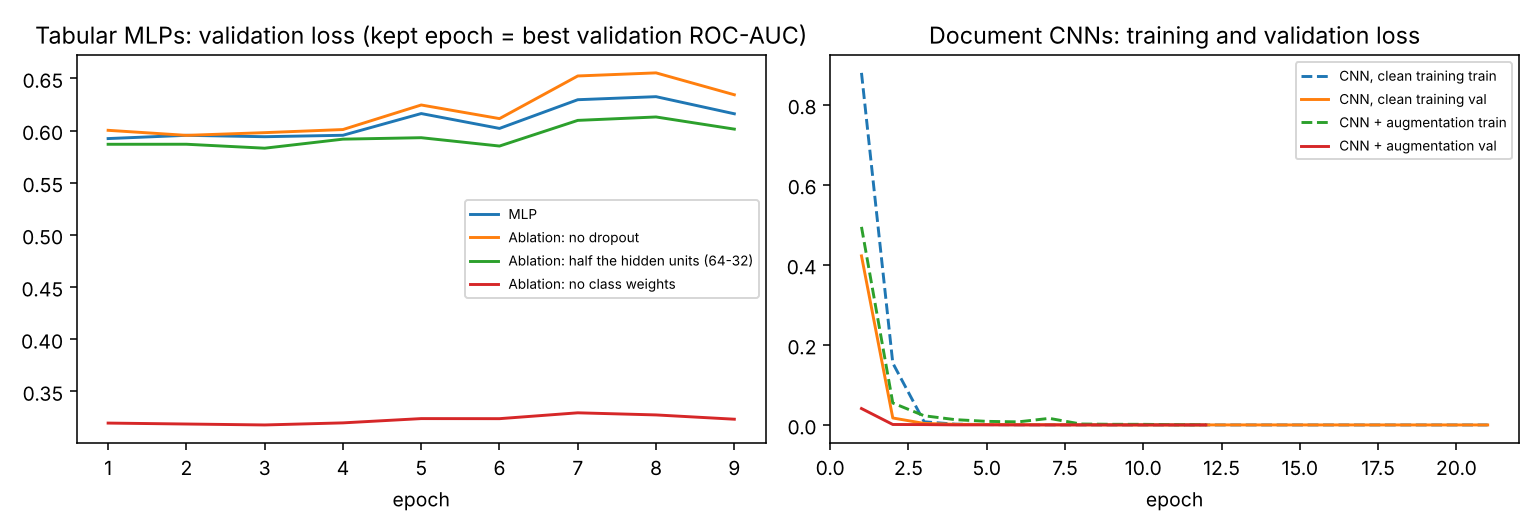

In [4]:
Image("outputs/training_curves.png")

**Why the MLP kept epoch 1.** The left chart shows validation loss rising after the first pass through the data, while training loss keeps falling (0.597 → 0.546 over 9 epochs). That gap means the network started **memorizing the training members** instead of learning anything new. Early stopping watches validation ROC-AUC (0.760 after epoch 1, then lower) and keeps the epoch-1 weights. The right chart shows the CNN learning steadily for many epochs, because pictures have real structure for convolutions to find.

,model,training_images,val_accuracy,test_accuracy,test_macro_f1,test_ece,messy_accuracy,messy_macro_f1,messy_ece,params,train_seconds
0,"CNN, clean training",840,1.0,1.0,1.0,0.0,0.9033,0.9019,0.0669,132451,7.49
1,CNN + augmentation,2520,1.0,1.0,1.0,0.0,0.9700,0.9700,0.0233,132451,11.70


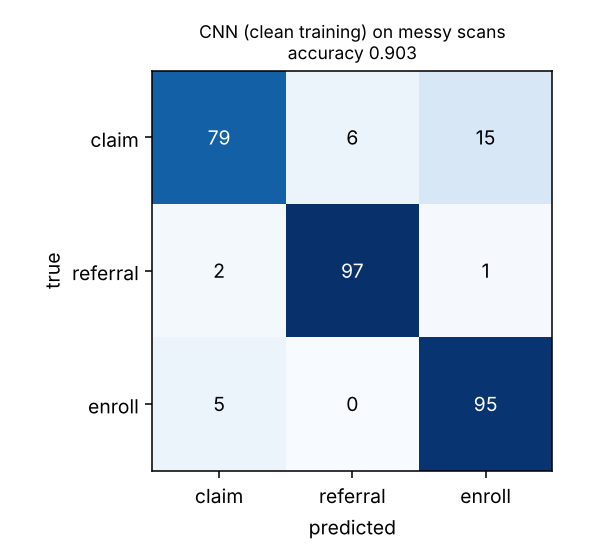

In [5]:
vis = pd.read_csv("outputs/comparison_vision.csv"); display(vis)
Image("outputs/cnn_confusion_messy.png")

## The deep track: a CNN on the AI Part 2 documents

| Model | Clean test | Messy scans |
|---|---|---|
| AI Part 2 softmax, clean training | 100% | 78.0% |
| **CNN, clean training** | 100% | **90.3%** |
| AI Part 2 softmax + augmentation | 100% | 99.7% |
| CNN + augmentation | 100% | 97.0% |

**Without augmentation, the CNN beats the softmax by 12 points on messy scans.** The softmax learned *where* ink sits on the page. The CNN slides small 3 x 3 pattern detectors across the whole image and then pools them, so a checkbox counts as a checkbox wherever it lands. That built-in tolerance for shifts is its **inductive bias**.

**With augmentation, the softmax actually edges out the CNN** (99.7% vs 97.0%). Once the softmax has practiced on tilted copies, it doesn't need the CNN's shift tolerance for documents this simple. Honest result: the CNN wins when training data is clean and limited, which is when you need it most.

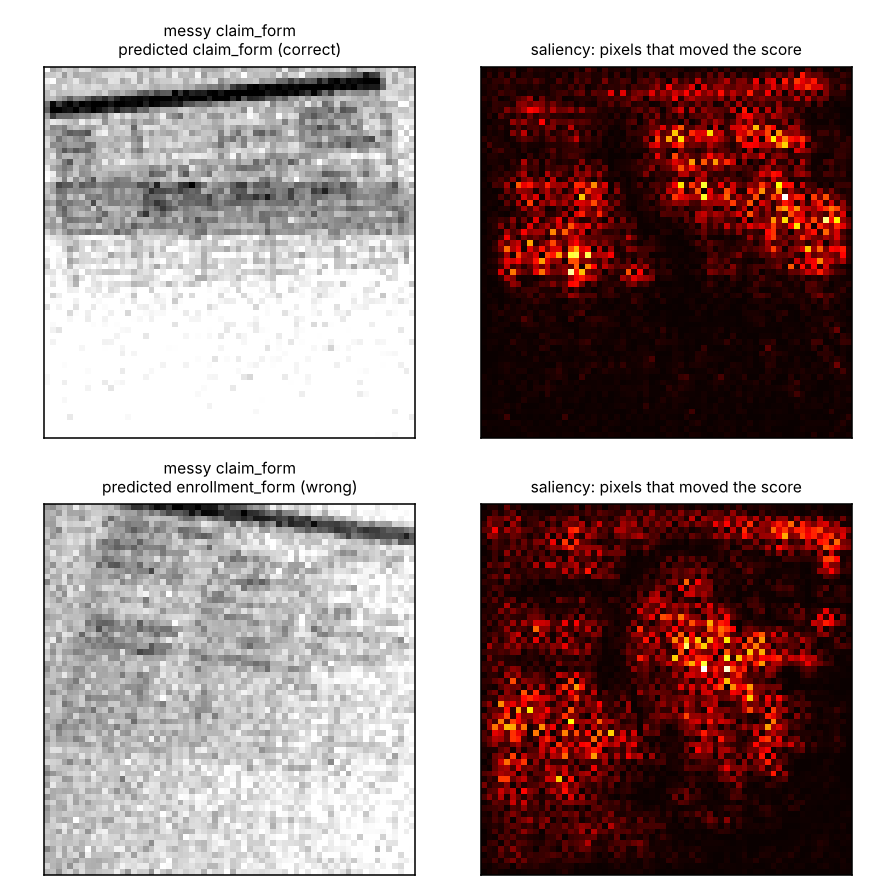

In [6]:
Image("outputs/cnn_saliency.png")

**Saliency maps** show which pixels changed the CNN's score the most (brighter = mattered more).
- **Top (correct):** the bright pixels sit on the claim form's grid of boxes, which is the right evidence.
- **Bottom (wrong):** a heavily tilted, noisy claim form read as an enrollment form. The attention is spread across noise and the left edge instead of a clear grid. The model guessed because the evidence was smeared.

In [7]:
h = m["hmm"]
print("High-cost spell line (last-3-month cost):", h["spell_line_dollars"])
print("Transition (rows = now, columns = next month; 0 = normal, 1 = spell):", h["transition"])
print("Emission (cost band 0 <$100, 1 $100-999, 2 $1k-5k, 3 $5k+):", h["emission"])
ex = h["viterbi_example"]
display(pd.DataFrame({"month": ex["months"], "cost band seen": ex["cost_band"], "Viterbi state": ex["viterbi_state"]}).T)

High-cost spell line (last-3-month cost): 4033.95
Transition (rows = now, columns = next month; 0 = normal, 1 = spell): [[0.9685, 0.0315], [0.3142, 0.6858]]
Emission (cost band 0 <$100, 1 $100-999, 2 $1k-5k, 3 $5k+): [[0.5128, 0.425, 0.0622, 0.0001], [0.1744, 0.3459, 0.2564, 0.2234]]


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02
cost band seen,1,1,0,0,0,3,0,1,0,0,3,2,1,0
Viterbi state,0,0,0,0,0,1,0,0,0,0,1,1,0,0


## The probabilistic model: an HMM

Think of it as weather. You can't see the season directly (the **hidden state**), but you can see today's temperature (the **observation**).
- **Hidden state:** is the member in a **high-cost spell** right now? (Last 3 months of cost above \$4,034.)
- **What we see each month:** the cost band of that month's claims.
- **Counting with +1 pseudo-counts** (Laplace smoothing) gives three tables, and every number is readable:
  - A normal member has a **3.2%** chance of starting a spell next month. A member in a spell has a **68.6%** chance of staying in it.
  - In a spell, **22%** of months are \$5,000+. In normal times that's almost never (0.01%).
- **Viterbi** finds the most likely hidden path. The example member flips into a spell in a \$5,000+ month and back out when the bills calm down.

**As a predictor it's weaker** (ROC-AUC 0.673), because it only sees the cost band and ignores age and conditions. But it has the **best calibration** (ECE 0.010), and you can explain every number to a care manager. That's when an HMM beats a deep net: small data, need for transparency, or wanting explicit uncertainty about a hidden state.

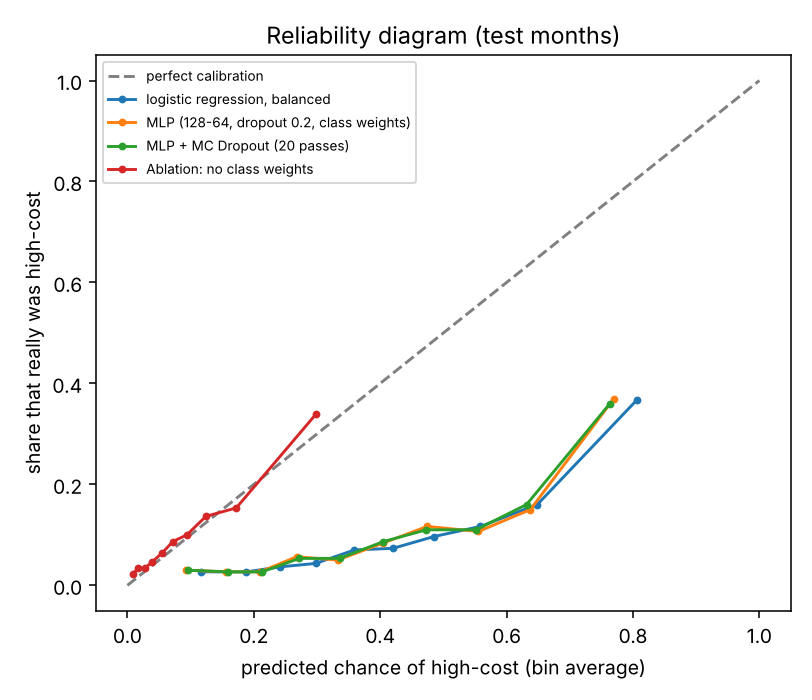

In [8]:
Image("outputs/reliability_diagram.png")

## Uncertainty and calibration

**ECE (expected calibration error)** asks: when the model is 80% sure of its answer, is it right 80% of the time? The assignment's ECE checks the confidence of the *chosen* answer, and every model scores low (0.010 to 0.108).

**The reliability diagram tells a sharper story about P(high-cost).** The models trained with class weights (balanced LR and the MLP) **overstate risk by about 2 to 3 times**. When they say 60%, only about 15% really become high-cost. That's the price of weighting: we told the model to fear misses, so it inflates every probability. The **unweighted MLP (red) sits right on the diagonal**, so its probabilities can be trusted, but it catches only 3.9% of high-cost members at the 0.5 line.

**Decision:** use the weighted model to **rank** members, and use calibrated probabilities (or recalibrate) whenever a dollar decision depends on the actual percentage. The capstone sets the threshold from costs.

In [9]:
display(pd.DataFrame(m["mc_dropout_most_uncertain"]))

,member_id,month,age,chronic_conditions,er_visits_6m,cost_prior_12m,p_high_mc,sd_mc,truly_high,cost_next_3m
0,M1150,2026-02,56,1,2,60270.37,0.574,0.167,0,1841.33
1,M0080,2026-02,68,3,0,53953.58,0.593,0.140,0,2835.51
2,M1455,2026-02,40,1,1,98114.18,0.337,0.139,0,142.85
3,M1455,2026-01,40,1,1,98158.99,0.366,0.135,0,112.38


**MC Dropout** keeps dropout switched on and asks the MLP the same question 20 times. The spread of the answers is its uncertainty. The four most uncertain test rows share a pattern: **a huge cost last year** (\$54k to \$98k) with **few other warning signs**. The model can't decide if that was a one-time event. All four turned out not to be high-cost next quarter. Those are exactly the members a person should review instead of trusting the flag (human in the loop).

In [10]:
abl = tab[tab.model.str.startswith(("MLP (", "Ablation"))][["model", "test_macro_f1", "test_recall_high", "test_roc_auc", "test_pr_auc", "params"]]
base = abl.iloc[0]
for c in ["test_macro_f1", "test_recall_high", "test_roc_auc", "test_pr_auc"]:
    abl[c + "_delta"] = (abl[c] - base[c]).round(4)
display(abl)

,model,test_macro_f1,test_recall_high,test_roc_auc,test_pr_auc,params,test_macro_f1_delta,test_recall_high_delta,test_roc_auc_delta,test_pr_auc_delta
2,"MLP (128-64, dropout 0.2, class weights)",0.5653,0.6525,0.7553,0.3344,10690,0.0000,0.0000,0.0000,0.0000
3,Ablation: no dropout,0.5697,0.6328,0.7543,0.3357,10690,0.0044,-0.0197,-0.0010,0.0013
4,Ablation: half the hidden units (64-32),0.5784,0.6393,0.7551,0.3344,3298,0.0131,-0.0132,-0.0002,0.0000
5,Ablation: no class weights,0.5117,0.0393,0.7464,0.3184,10690,-0.0536,-0.6132,-0.0089,-0.0160


## Ablations (remove one piece, see what changes)

| Change | Recall change | ROC-AUC change | What it shows |
|---|---|---|---|
| Remove dropout | −0.020 | −0.001 | Dropout barely matters, because training stops after 1 epoch anyway |
| Halve hidden units (3,298 params) | −0.013 | −0.000 | A third of the size, same ranking skill. The big network is wasted |
| **Remove class weights** | **−0.613** | −0.009 | **The single most important choice.** Without weights, recall collapses to 3.9% |

The ablations confirm the main lesson. **How the problem is framed** (class weights for a rare outcome) matters far more than the network's shape.

In [11]:
print(m["error_counts"])
display(pd.DataFrame(m["error_examples"]))
display(pd.DataFrame(m["subgroups"]))

{'False alarm: risky profile (age, conditions), stayed low': 589, 'False alarm: expensive last year, quiet next quarter': 174, 'Missed: warning signs, but under the line': 55, 'Missed: little history, then a big quarter': 51}


,error_type,age,chronic_conditions,er_visits_6m,cost_prior_12m,p_high,cost_next_3m
0,"False alarm: expensive last year, quiet next q...",61,2,0,23959.21,0.648,612.04
1,"False alarm: expensive last year, quiet next q...",62,3,2,22683.47,0.619,2027.68
2,"False alarm: risky profile (age, conditions), ...",71,2,0,3350.42,0.524,735.05
3,"False alarm: risky profile (age, conditions), ...",54,3,2,11750.59,0.615,3149.64
4,"Missed: little history, then a big quarter",40,0,0,2514.13,0.257,5377.79
5,"Missed: little history, then a big quarter",29,1,0,2196.67,0.117,6124.85
6,"Missed: warning signs, but under the line",48,3,0,4143.91,0.481,6627.81
7,"Missed: warning signs, but under the line",73,1,0,5602.82,0.487,5856.12


,group,rows,high_cost_rate,flag_rate,recall
0,age_band = 18-44,734,0.045,0.011,0.000
1,age_band = 45-64,1306,0.066,0.176,0.337
2,age_band = 65+,960,0.194,0.754,0.914
3,plan_type = Marketplace,913,0.074,0.206,0.250
4,plan_type = Medicaid,1099,0.044,0.045,0.250
5,plan_type = Medicare Advantage,946,0.195,0.758,0.918
6,plan_type = Unknown,42,0.119,0.190,0.200
7,county = Broward,1082,0.103,0.286,0.631
8,county = Miami-Dade,1918,0.101,0.340,0.665


## Error analysis

The MLP's 869 mistakes on the test months fall into four groups:

| Error type | Count | Cause |
|---|---|---|
| False alarm: risky profile, stayed low | 589 | Class overlap. Many older members with conditions never become high-cost |
| False alarm: expensive last year, quiet next quarter | 174 | A one-time event (surgery, accident) that doesn't repeat |
| Missed: warning signs, but under the line | 55 | Close calls (probabilities 0.45 to 0.50) |
| Missed: little history, then a big quarter | 51 | Unpredictable: nothing in the record pointed to it |

The last group is the honest limit of any model. A sudden first hospital stay can't be predicted from claims history.

## Fairness check (subgroup recall)

- **Ages 65+ / Medicare Advantage:** recall about 91%, but 75% of them get flagged.
- **Ages 18 to 44:** recall **0%**. The model never flags them, even though 4.5% become high-cost.
- **Medicaid:** recall 25%.
- **County:** no real gap (63% vs 67%).

Part of this is a **base-rate difference**: older members really are high-cost more often (19% vs 4.5%). But the **error-rate difference** is far bigger than the 0.10 recall gap the capstone allows, so younger and Medicaid members who do become high-cost are mostly missed. **Mitigations:** separate thresholds by age band, adding signals beyond age (ER use, pharmacy), and a human review queue for young members with sudden ER visits.

## Ethics and responsible AI
- **Overconfidence:** weighted models inflate percentages, so don't show raw probabilities to care managers without recalibrating.
- **Dataset artifacts:** the data is synthetic and I wrote its rules (for example, the distance effect), so these results show the method, not real-world truth.
- **Transparency vs. performance:** the HMM and logistic regression are readable, and the MLP adds nothing here. Choose the readable one.
- **Human in the loop:** uncertain or high-impact cases (high MC variance, big one-time costs) go to a person. The flag is for **outreach, never for denying care.**

**Summary.** The MLP ties logistic regression, so the simpler model stays champion. The CNN reads messy scans 12 points better than the softmax when training data is clean. The HMM gives a readable picture of high-cost spells. Class weighting is the single biggest lever, and it also distorts probabilities. Younger and Medicaid members are under-served by the flag.